1 — Imports + paths + sys.path

In [1]:
import sys, random
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

R2GEN_REPO = Path("/home/psivakumar/thesis/code/R2GenCMN")
ANN_PATH   = Path("/home/psivakumar/thesis/data/iu_xray/annotation_r2gencmn_2view_r2gencmnformat.json")
IMAGE_ROOT = Path("/home/psivakumar/thesis/data/iu_xray/images")

BEST_CKPT  = Path("/home/psivakumar/thesis/code/R2GenCMN/outputs/iu_xray_r2gencmn_baseline_5ep/current_checkpoint.pth")

OUT_DIR = Path("/home/psivakumar/thesis/notebooks/xai_outputs_r2gencmn")
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert R2GEN_REPO.exists(), f"Missing repo: {R2GEN_REPO}"
assert ANN_PATH.exists(),   f"Missing ann: {ANN_PATH}"
assert IMAGE_ROOT.exists(), f"Missing images: {IMAGE_ROOT}"
assert BEST_CKPT.exists(),  f"Missing ckpt: {BEST_CKPT}"

sys.path.insert(0, str(R2GEN_REPO))

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
print("Output dir:", OUT_DIR)

Device: cuda
Output dir: /home/psivakumar/thesis/notebooks/xai_outputs_r2gencmn


2 — Build args + tokenizer + dataset

In [2]:
from torchvision import transforms
from torch.utils.data import DataLoader

from modules.tokenizers import Tokenizer
from modules.datasets import IuxrayMultiImageDataset

class Args: 
    pass

args = Args()
args.dataset_name   = "iu_xray"
args.ann_path       = str(ANN_PATH)
args.image_dir      = str(IMAGE_ROOT)
args.max_seq_length = 100
args.threshold      = 3

args.visual_extractor = "resnet101"
args.visual_extractor_pretrained = True

args.num_layers   = 3
args.num_heads    = 8
args.d_model      = 512
args.d_ff         = 2048
args.d_vf         = 2048
args.dropout      = 0.1
args.drop_prob_lm = 0.1
args.use_bn       = 0
args.topk         = 32

# CMN memory defaults
args.cmm_size = 512
args.cmm_dim  = 512

# Tokenizer
tokenizer = Tokenizer(args)
tokenizer.pad_idx = 0
tokenizer.bos_idx = 0
tokenizer.eos_idx = 0
tokenizer.unk_idx = tokenizer.token2idx.get("<unk>", 0)

args.pad_idx = tokenizer.pad_idx
args.bos_idx = tokenizer.bos_idx
args.eos_idx = tokenizer.eos_idx
args.unk_idx = tokenizer.unk_idx

print("Tokenizer vocab:", tokenizer.get_vocab_size())

# Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

# Dataset + loader
test_dataset = IuxrayMultiImageDataset(args=args, tokenizer=tokenizer, split="test", transform=transform)
test_loader  = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=0)

print("Test samples:", len(test_dataset))

Tokenizer vocab: 928
Test samples: 44


In [3]:
# from pathlib import Path

# # Correct base folder
# NORMALISED_ROOT = "/home/psivakumar/thesis/data/iu_xray/images/normalised_images"

# # Patch dataset paths
# for split in ["train", "val", "test"]:
#     for ex in test_dataset.examples:
#         ex["image_path"] = [
#             str(Path("normalised_images") / Path(p).name)
#             for p in ex["image_path"]
#         ]

# args.image_dir = "/home/psivakumar/thesis/data/iu_xray/images"
# print("Dataset paths patched to normalised_images/")


3 — Load checkpoint and infer correct shapes

In [4]:
ckpt = torch.load(str(BEST_CKPT), map_location="cpu")
state_dict = ckpt["state_dict"] if isinstance(ckpt, dict) and "state_dict" in ckpt else ckpt

# infer d_model & d_ff from checkpoint
ff_key = next((k for k in state_dict.keys() if "feed_forward.w_1.weight" in k), None)
if ff_key:
    d_ff_ckpt, d_model_ckpt = state_dict[ff_key].shape
    args.d_model = int(d_model_ckpt)
    args.d_ff    = int(d_ff_ckpt)
    print("From ckpt: d_model =", args.d_model, "| d_ff =", args.d_ff)
    

# infer CMN memory matrix dims
mem_key = "encoder_decoder.memory_matrix"
if mem_key in state_dict:
    args.cmm_size, args.cmm_dim = map(int, state_dict[mem_key].shape)
    print("From ckpt: cmm_size =", args.cmm_size, "| cmm_dim =", args.cmm_dim)

print("Ready to build model")

/tmp/ipykernel_583452/3199950624.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt = torch.load(str(BEST_CKPT), map_location="cpu")


From ckpt: d_model = 512 | d_ff = 512
From ckpt: cmm_size = 2048 | cmm_dim = 512
Ready to build model


4 — Build model + load weights

In [5]:
from models.models import BaseCMNModel

model = BaseCMNModel(args, tokenizer).to(DEVICE)
incompat = model.load_state_dict(state_dict, strict=False)
model.eval()

print("Model loaded")
print("Missing keys:", len(incompat.missing_keys))
print("Unexpected keys:", len(incompat.unexpected_keys))

/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/home/psivakumar/.conda/envs/ml/lib/python3.10/site-packages/torch/cuda/__init__.py:716: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")


Model loaded
Missing keys: 0
Unexpected keys: 0


5 — Helpers (denorm, overlay, decoding)

In [10]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406])
IMAGENET_STD  = np.array([0.229, 0.224, 0.225])

def tensor_to_rgb(img_t):
    """img_t: (3,224,224) normalized tensor -> RGB (H,W,3) in [0,1]"""
    x = img_t.detach().cpu().numpy().transpose(1,2,0)
    x = (x * IMAGENET_STD) + IMAGENET_MEAN
    return np.clip(x, 0, 1)

def overlay_heatmap(rgb, cam, alpha=0.45):
    """
    rgb: (H,W,3) in [0,1]
    cam: (H,W) in [0,1]
    returns: overlay RGB
    """
    # use matplotlib colormap for "heat"
    heat = plt.cm.jet(cam)[..., :3]  # (H,W,3)
    out = (1 - alpha) * rgb + alpha * heat
    return np.clip(out, 0, 1)

# def decode_gt(report_ids_1d):
#     # same convention in trainer: decode report_ids[:, 1:]
#     arr = report_ids_1d[1:].detach().cpu().numpy()[None, :]
#     return tokenizer.decode_batch(arr)[0]
import torch
import numpy as np

def decode_gt(report_ids_1d):
    if isinstance(report_ids_1d, list):
        ids = torch.tensor(report_ids_1d, dtype=torch.long)
    elif isinstance(report_ids_1d, np.ndarray):
        ids = torch.from_numpy(report_ids_1d).long()
    else:
        ids = report_ids_1d  # torch tensor

    arr = ids[1:].cpu().numpy()[None, :]   # (1, seq_len-1)
    return tokenizer.decode_batch(arr)[0]

6 — Find a good Grad-CAM target layer (last Conv2d in visual extractor)

In [7]:
import torch.nn as nn

def find_last_conv(module: nn.Module):
    last = None
    for m in module.modules():
        if isinstance(m, nn.Conv2d):
            last = m
    return last

cnn = model.visual_extractor.model  # Sequential CNN
target_layer = find_last_conv(cnn)
print("CNN type:", type(cnn))
print("Grad-CAM target layer:", target_layer)
assert target_layer is not None, "Could not find any Conv2d layer for Grad-CAM."

CNN type: <class 'torch.nn.modules.container.Sequential'>
Grad-CAM target layer: Conv2d(512, 2048, kernel_size=(1, 1), stride=(1, 1), bias=False)


7 — Grad-CAM Engine (clean + stable)

In [8]:
import torch.nn.functional as F

class GradCAM:
    def __init__(self, model_cnn, target_layer):
        self.model_cnn = model_cnn
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self._register_hooks()

    def _register_hooks(self):
        def fwd_hook(_, __, output):
            self.activations = output

        def bwd_hook(_, grad_in, grad_out):
            # grad_out[0] is gradient wrt output of the layer
            self.gradients = grad_out[0]

        self.target_layer.register_forward_hook(fwd_hook)
        self.target_layer.register_full_backward_hook(bwd_hook)

    def __call__(self, x, target_scalar=None):
        """
        x: (1,3,224,224) tensor
        target_scalar: callable(feats)->scalar OR None (default: feats.mean())
        returns cam: (224,224) numpy in [0,1]
        """
        self.model_cnn.zero_grad(set_to_none=True)
        x = x.requires_grad_(True)

        feats = self.model_cnn(x) 

        if target_scalar is None:
            score = feats.mean()   
        else:
            score = target_scalar(feats)

        score.backward(retain_graph=False)

        # activations: (1,C,h,w), gradients: (1,C,h,w)
        A = self.activations
        G = self.gradients

        weights = G.mean(dim=(2,3), keepdim=True)         # (1,C,1,1)
        cam = (weights * A).sum(dim=1, keepdim=True)      # (1,1,h,w)
        cam = F.relu(cam)

        cam = F.interpolate(cam, size=(224,224), mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()

        cam = cam - cam.min()
        cam = cam / (cam.max() + 1e-8)
        return cam

cam_engine = GradCAM(cnn, target_layer)
print("GradCAM ready")

GradCAM ready


8 — Pick random UID, generate report, compute CAM for both views, show + save

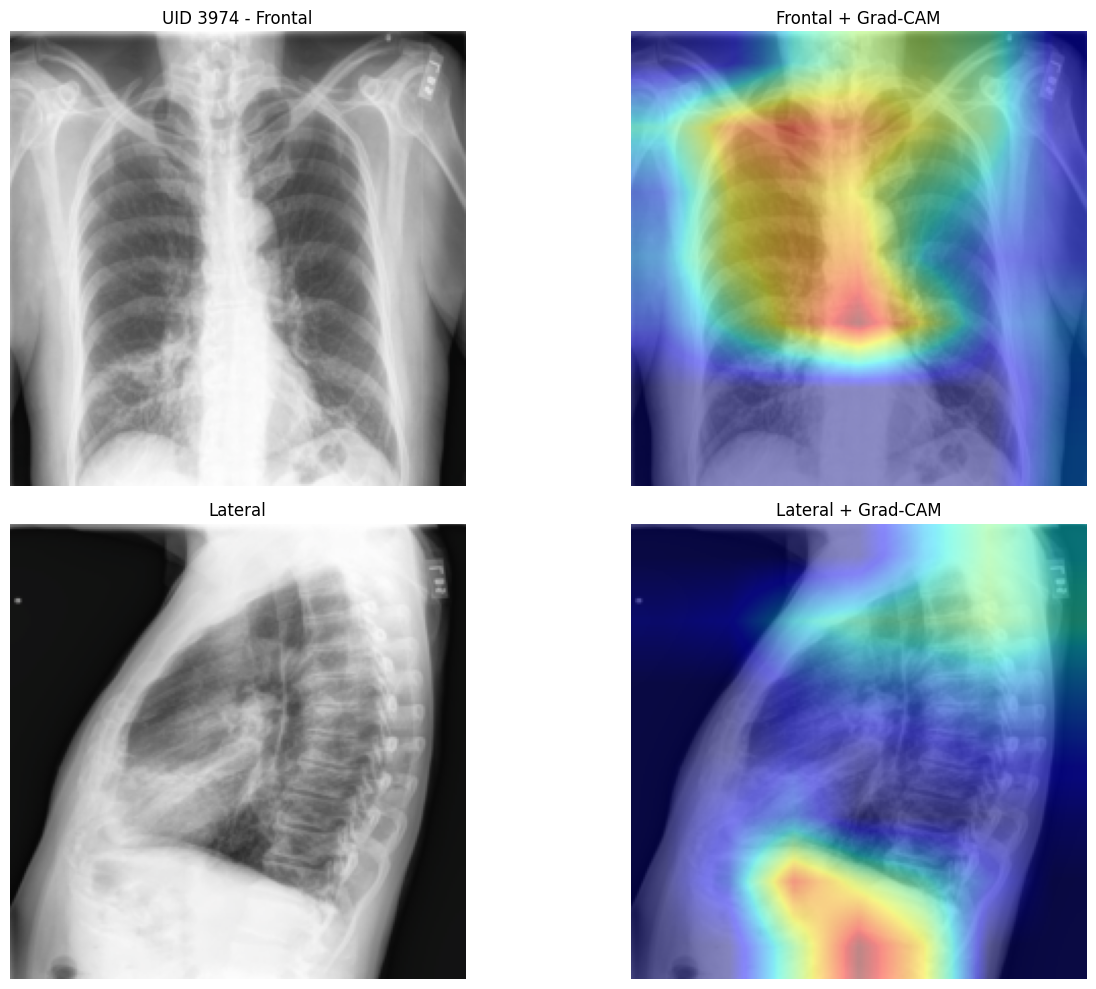


==================== GT ====================
the lungs are hyperexpanded consistent with emphysema . the heart size and pulmonary vascularity appear within normal limits . no pneumothorax or pleural effusion is seen . patchy airspace disease is present in the right middle lobe . degenerative changes are present spine . impression hyperexpanded lungs suggesting emphysema . patchy right middle lobe airspace disease . may represent pneumonia . followup examination is <unk> following treatment to <unk> <unk> of the opacities . a 4 to 6 xxxx post treatment interval film would be <unk> to <unk> <unk> of inflammatory opacities .

=================== PRED ===================
the heart is normal in size . the mediastinum is stable . the aorta is atherosclerotic . atherosclerotic . the lungs are clear . impression no acute disease .

Saved:
/home/psivakumar/thesis/notebooks/xai_outputs_r2gencmn/uid_3974_20260110_124528_frontal.png
/home/psivakumar/thesis/notebooks/xai_outputs_r2gencmn/uid_3974_

In [11]:
from datetime import datetime

# pick random sample
idx = random.randint(0, len(test_dataset)-1)
uid, images_2view, report_ids, report_masks, seq_len = test_dataset[idx]

# Predict report using full model
images_batch = images_2view.unsqueeze(0).to(DEVICE)  # (1,2,3,224,224)

with torch.no_grad():
    out = model(images_batch, mode="sample")
if isinstance(out, tuple):
    out = out[0]

pred = tokenizer.decode_batch(out.cpu().numpy())[0]
gt   = decode_gt(report_ids)

# CAM per view using CNN directly
view0 = images_2view[0].unsqueeze(0).to(DEVICE)  # frontal
view1 = images_2view[1].unsqueeze(0).to(DEVICE)  # lateral

cam0 = cam_engine(view0)
cam1 = cam_engine(view1)

# Convert to RGB for display
rgb0 = tensor_to_rgb(images_2view[0])
rgb1 = tensor_to_rgb(images_2view[1])

ov0 = overlay_heatmap(rgb0, cam0, alpha=0.45)
ov1 = overlay_heatmap(rgb1, cam1, alpha=0.45)

# Plot
plt.figure(figsize=(14,10))

plt.subplot(2,2,1); plt.imshow(rgb0); plt.title(f"UID {uid} - Frontal"); plt.axis("off")
plt.subplot(2,2,2); plt.imshow(ov0);  plt.title("Frontal + Grad-CAM"); plt.axis("off")
plt.subplot(2,2,3); plt.imshow(rgb1); plt.title("Lateral"); plt.axis("off")
plt.subplot(2,2,4); plt.imshow(ov1);  plt.title("Lateral + Grad-CAM"); plt.axis("off")

plt.tight_layout()
plt.show()

print("\n==================== GT ====================")
print(gt)
print("\n=================== PRED ===================")
print(pred)

# Save images to disk
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
save_prefix = OUT_DIR / f"uid_{uid}_{stamp}"

plt.imsave(str(save_prefix) + "_frontal.png", rgb0)
plt.imsave(str(save_prefix) + "_lateral.png", rgb1)
plt.imsave(str(save_prefix) + "_frontal_cam.png", ov0)
plt.imsave(str(save_prefix) + "_lateral_cam.png", ov1)

# Save text
with open(str(save_prefix) + "_reports.txt", "w") as f:
    f.write("UID: " + str(uid) + "\n\n")
    f.write("GT:\n" + gt + "\n\n")
    f.write("PRED:\n" + pred + "\n")

print("\nSaved:")
print(str(save_prefix) + "_frontal.png")
print(str(save_prefix) + "_lateral.png")
print(str(save_prefix) + "_frontal_cam.png")
print(str(save_prefix) + "_lateral_cam.png")
print(str(save_prefix) + "_reports.txt")

9 — (Optional) Run XAI on N random samples and save a small gallery

In [13]:
N = 5
picked = random.sample(range(len(test_dataset)), k=min(N, len(test_dataset)))
print("Running XAI for indices:", picked)

for idx in picked:
    uid, images_2view, report_ids, _, _ = test_dataset[idx]

    images_batch = images_2view.unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = model(images_batch, mode="sample")
    if isinstance(out, tuple):
        out = out[0]

    pred = tokenizer.decode_batch(out.cpu().numpy())[0]
    gt   = decode_gt(report_ids)

    view0 = images_2view[0].unsqueeze(0).to(DEVICE)
    view1 = images_2view[1].unsqueeze(0).to(DEVICE)

    cam0 = cam_engine(view0)
    cam1 = cam_engine(view1)

    rgb0 = tensor_to_rgb(images_2view[0])
    rgb1 = tensor_to_rgb(images_2view[1])
    ov0 = overlay_heatmap(rgb0, cam0, alpha=0.45)
    ov1 = overlay_heatmap(rgb1, cam1, alpha=0.45)

    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    save_prefix = OUT_DIR / f"uid_{uid}_{stamp}"

    plt.imsave(str(save_prefix) + "_frontal_cam.png", ov0)
    plt.imsave(str(save_prefix) + "_lateral_cam.png", ov1)

    with open(str(save_prefix) + "_reports.txt", "w") as f:
        f.write("UID: " + str(uid) + "\n\n")
        f.write("GT:\n" + gt + "\n\n")
        f.write("PRED:\n" + pred + "\n")

print("Batch XAI complete. Check:", OUT_DIR)

Running XAI for indices: [30, 28, 4, 5, 13]
Batch XAI complete. Check: /home/psivakumar/thesis/notebooks/xai_outputs_r2gencmn


📁 UID folder: .ipynb_checkpoints

================ REPORT =================

UID: 536

GT:
no acute osseous abnormality . the soft tissues are within normal limits . normal cardiomediastinal silhouette and hilar contours . no focal area of consolidation pleural effusion or pneumothorax . impression no acute radiographic cardiopulmonary process .

PRED:
the heart and lungs have xxxx xxxx xxxx in the interval . both lungs are clear and expanded . heart and mediastinum normal . impression no active disease .



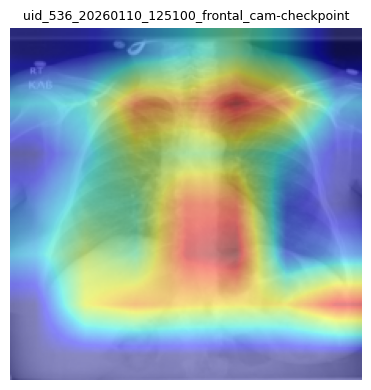

In [23]:
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

# XAI output root
XAI_DIR = Path("/home/psivakumar/thesis/notebooks/xai_outputs_r2gencmn")

# Pick a random UID folder
uid_dir = random.choice([p for p in XAI_DIR.iterdir() if p.is_dir()])
print("📁 UID folder:", uid_dir.name)

# ----------------------------
# Print report text
# ----------------------------
txt_files = list(uid_dir.glob("*.txt"))
if txt_files:
    print("\n================ REPORT =================\n")
    print(txt_files[0].read_text())
else:
    print("❌ No report file found")

# ----------------------------
# Display all images
# ----------------------------
img_files = sorted(uid_dir.glob("*.png"))

if not img_files:
    raise RuntimeError("❌ No images found in folder")

fig, axes = plt.subplots(1, len(img_files), figsize=(4 * len(img_files), 4))
if len(img_files) == 1:
    axes = [axes]

for ax, img_path in zip(axes, img_files):
    img = Image.open(img_path).convert("RGB")
    ax.imshow(img)
    ax.set_title(img_path.name.replace(".png", ""), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()